# Unit 7 Building a square wave with a Fourier series

We will be defining a function to calculate the terms in the Fourier sequence, then plotting Fourier waves and analysing them.

<div class="alert alert-success">
<h2> The task: </h2>
<br>
This is a template for the unit 7 Fourier Square Wave task. Your job is to fill in the blanks in the code and add text cells where needed. 
<br>
All the instructions for the task are in green text cells like this one. You can keep these cells in your submitted notebook if you want, but they will be ignored by the markers.
<br>
You will be graded on your completed code, and the text cells that you add yourself. Some template text cells are already added, but feel free to add more.
</div>

<div class="alert alert-success">
Replace the title/header of this notebook with your own title, and include a suitable introduction. (You can leave this until the end, but don't forget!)
<div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# The line below changes the default figure size. 
# You may want to edit it to taste or comment it out depending on the size of your screen.
# Don't make the figure so large that you also need to adjust the text size though!
# The default proportions are there for a reason.
plt.figure()
plt.rcParams['figure.figsize'] = 12, 6

<Figure size 640x480 with 0 Axes>

<div class="alert alert-success">
The code cell below defines our initial data. A value for $L$, the half-period of the function, has already been set. Add a line that will create an array, named <tt>x</tt>, of values to use for the x-values for the plot from $-10$ to $+10$, with an appropriate number of points to result in a smooth function on the plot. (You can come back and adjust this later).
<div>


In [10]:
### Set up initial data
L = 5.     # period of the function is [−L,L]
##### STUDENT COMPLETED LINE #####
x = np.linspace(-10, 10, 1000)
###################################

<div class="alert alert-success">
The code cell below contains the start of a function that needs to calculate the Fourier series for a square wave, i.e. it codes the mathematical function
$$f_\text{square}(x) = \frac{4}{\pi} \sum_{n = 1, 3, 5, \ldots}^{\infty} \frac{1}{n} \sin\left(\frac{n \pi x}{L}\right) \qquad \qquad (1)$$ 
for all $n$ up to and including $n = $ <tt>n_max</tt> (as we will need to truncate our series at some finite point rather than continuing all the way to $n = \infty$). The docstring has already been written for you.

<ul>
<li>
Complete the function to calculate the Fourier series including the terms for all values of $n$ up to <tt>n_max</tt> specified in the function input. </li>
<li> <b>Don't change any of the variable names or the docstring. </b>Follow the specification given. </li>
<li>Use appropriate code comments to explain how your function works.</li>
</ul>

<b> Note:</b> Here the variable <tt>L</tt> will act as a _global_ variable. It is defined in the cell above, and when you reference <tt>L</tt> in your function it will use that value of <tt>L</tt>, without having to explicitly pass it to the function. In other words, you don't need to redefine <tt>L</tt> within your function.

<b> HINTS:</b> You will need to use a loop, as you did in the series summation task in module 6. Think carefully about the differences and similarities between that summation and this one. In particular:
<ul>
<li>What are the start and end points of the summation?</li>
<li>Are we summing over all values of n? How will you deal with this?</li>
<li>Note that we're going to be calculating this for an array of x-values. However, as we saw in the Legendre polynomial example, this doesn't make any difference to the way the function is coded: it will automatically work either for a single x-value or an array.</li>
</ul>

<div>

In [11]:
def fourier_square(x,n_max):
    '''Creates the Fourier series for square wave.
    Inputs:
    x:       array of x-values or single x-value
    n_max:   maximum value of n in summation from eqn(1) above
    Depends on:
    L:       global variable determining period of square wave
    Returns:
    fourier: array of y-values or single y-value for Fourier square wave
    
    '''
    #### STUDENT COMPLETED CELL ####
    fourier_square = 0
    for n in range(1, n_max+1, 2 ):
        sequence = 1/n * np.sin ((n * np.pi * x)/L)
        fourier_square = fourier_square + sequence
    fourier_square = fourier_square * 4/np.pi
    return fourier_square

    ################################

<div class="alert alert-success">
The code cell below will allow you to check that your <tt>fourier_square</tt> function is working correctly. Does it generate the correct output for the given inputs? You should debug your function before proceeding. However, if you can't find the source of any problem it may be worth also writing the code that will plot the Fourier series (below), in case looking at a plot of the function over the whole x-range reveals the source of the problem.
</div>

In [12]:
# Check all is well before proceeding!
print(f"At x = 5 and n_max = 1, function returns {fourier_square(5,1)}.")
print("  Should be zero.")
print(f"At x = -2 and n_max = 7, function returns {fourier_square(-2,7)}.")
print("  Should be -1.06837....")

At x = 5 and n_max = 1, function returns 1.5592687330077502e-16.
  Should be zero.
At x = -2 and n_max = 7, function returns -1.0683720178191634.
  Should be -1.06837....


<div class="alert alert-success">
Now you should use your function to plot the Fourier series for different numbers of terms, investigate its behaviour, and write some conclusions. You may want to go further, but you should at least look at, and comment on what happens
<ul>
    <li>as <tt>n_max</tt> increases;</li>
    <li>when <tt>n_max</tt> changes between odd and even values, e.g. from 1 to 2, 2 to 3, and 3 to 4;</li>
    <li>when <tt>n_max</tt> becomes very large, say over 100;</li>
    <li>in regions where the function is changing rapidly.</li>
</ul>
You should think about how best to present your results, e.g. whether to plot different results on the same axes or separate ones. You can add further code and text cells as appropriate.
<div>

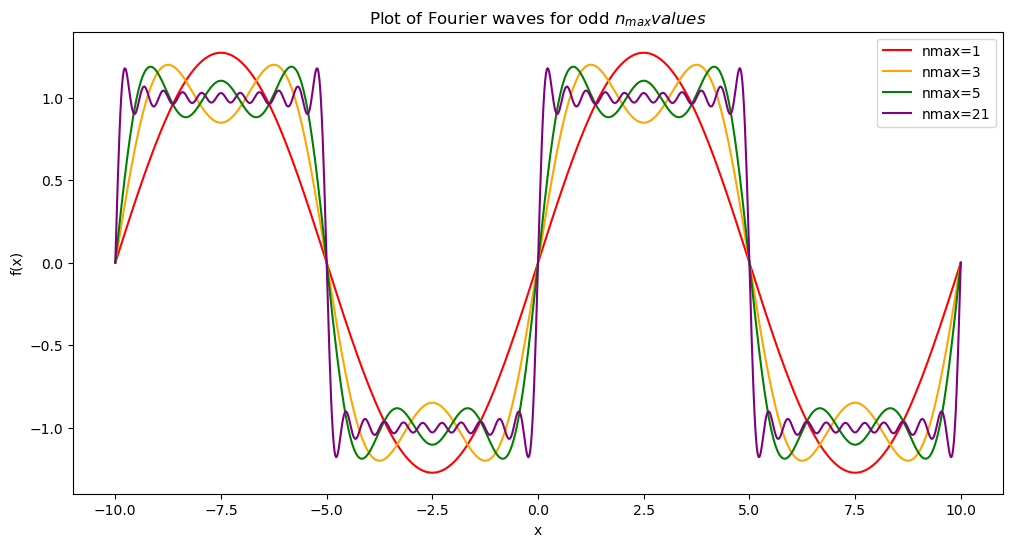

In [13]:
# Calling functions for various nm_max
fourier1 = fourier_square(x, 1) # changing n_max
fourier3 = fourier_square(x, 3)
fourier5 = fourier_square(x, 5)
fourier21 = fourier_square(x, 21)
# Set up graph
plt.figure()
plt.title("Plot of Fourier waves for odd $n_{max}  values$")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.plot(x, fourier1, color='red', label= 'nmax=1');
plt.plot(x, fourier3, color='orange', label= 'nmax=3');
plt.plot(x, fourier5, color='green', label = 'nmax=5');
plt.plot(x, fourier21, color='purple', label = 'nmax=21');
plt.legend();

We can see that, for odd small values of $n_{max}$, the waves oscillate more frequently at their minimas and maximas. However, at x values nearer to the saddle points, the waves fluctuate less. 

As $n_{max}$ increases, the orders of the polynomials at the minimas and maximas increases too. 
- For $n_{max}$ = 1, a sine wave can be seen with one oscillation.
- For $n_{max}$ = 3, a wave can be seen with three oscillations; two peaks and one trough.
- For $n_{max}$ = 3, a sine wave can be seen with five oscillations; three peaks and two troughs.

This pattern will continue for all odd values of $n_{max}$. This can be seen by plotting $n_{max}$ = 21, too. The amplitudes of the oscillations are also decreasing as $n_{max}$ increases. 

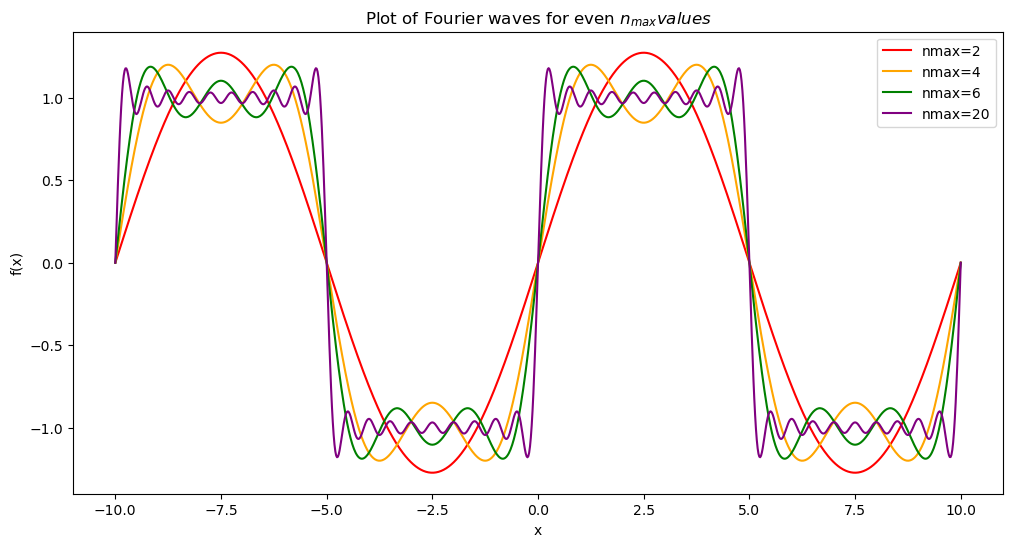

In [14]:
# Call functions at different n max values
fourier1 = fourier_square(x, 2) 
fourier3 = fourier_square(x, 4)
fourier5 = fourier_square(x, 6)
fourier20 = fourier_square(x, 20)
# Set up graph
plt.figure()
plt.title("Plot of Fourier waves for even $n_{max}  values$")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.plot(x, fourier1, color='red', label= 'nmax=2');
plt.plot(x, fourier3, color='orange', label= 'nmax=4');
plt.plot(x, fourier5, color='green', label = 'nmax=6');
plt.plot(x, fourier20, color='purple', label = 'nmax=20');
plt.legend();

We can see that plotting $n_{max}$ with even values has no effect on the plotted graphs because the Fourier series itself skips over even values of n. 

Now, we will see when $n_{max}$ reaches a very large number.

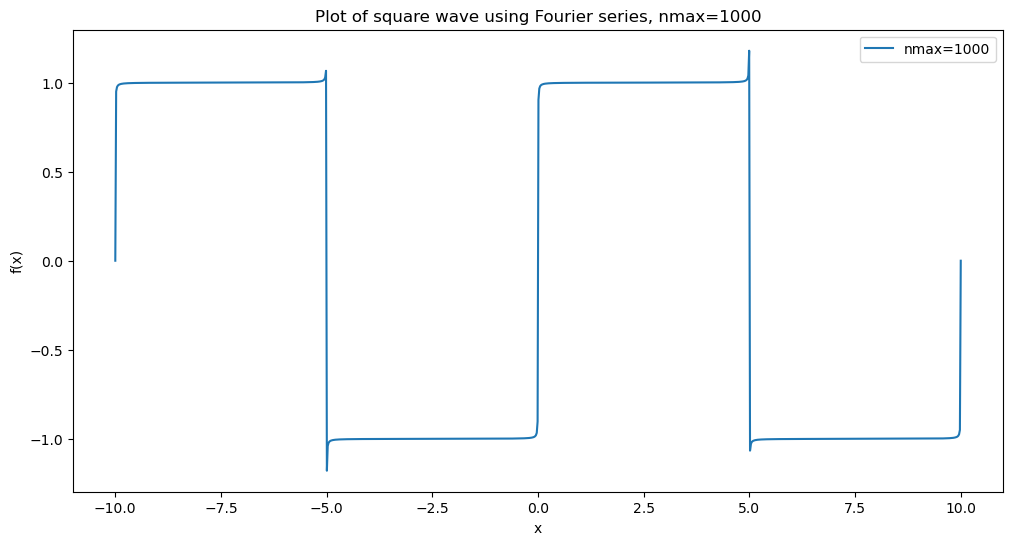

In [15]:
#### STUDENT COMPLETED CELL ##########
# Call function, set nmax (number of terms) to 1000
fourier = fourier_square(x, 1000)
# Set up graph
plt.figure()
plt.title("Plot of square wave using Fourier series, nmax=1000")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.plot(x, fourier, label= 'nmax=1000');
plt.legend();
# You may also add further code cells.
######################################

We can see that as $n_{max}$ is very large, the amplitude of the oscillations at the minimas and maximas of the waves reach a constant. 

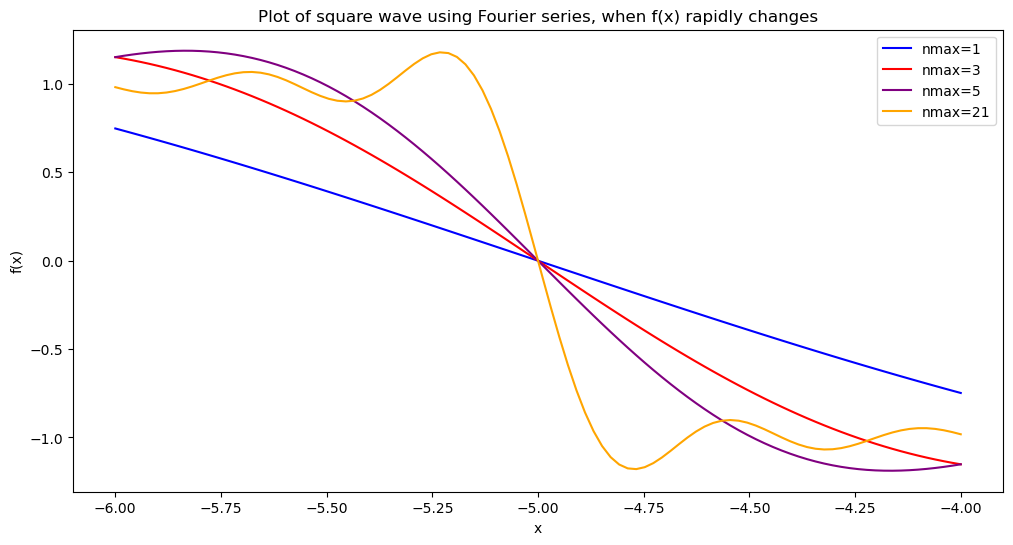

In [16]:
x2 = np.linspace(-6, -4, 100)
# Call functions
fourier1x2 = fourier_square(x2, 1)
fourier2x2 = fourier_square(x2, 3)
fourier3x2 = fourier_square(x2, 5)
fourier4x2 = fourier_square(x2, 21)
# Set up graph
plt.figure()
plt.title("Plot of square wave using Fourier series, when f(x) rapidly changes")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.plot(x2, fourier1x2, label= 'nmax=1', color = 'blue');
plt.plot(x2, fourier2x2, label= 'nmax=3', color = 'red');
plt.plot(x2, fourier3x2, label= 'nmax=5', color = 'purple');
plt.plot(x2, fourier4x2, label= 'nmax=21', color = 'orange');
# Legend
plt.legend();

The fourier lines cross at the same point, and as $n_{max}$ increases, we can clearly seee that the gradients of the curves become more steep and more like polynomials. For $n_{max}$ = 1, the gradient at the inlection point looks almost linear.

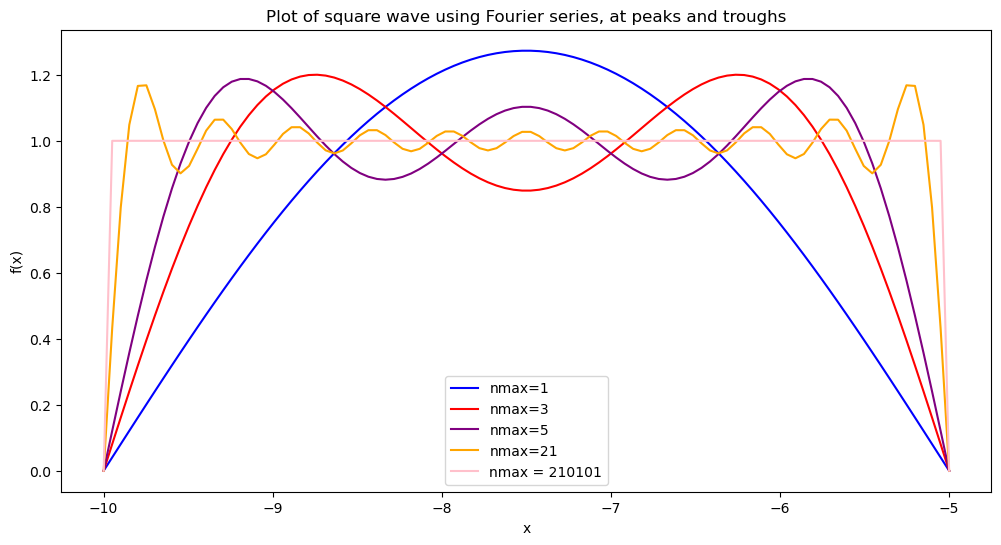

In [21]:
x3 = np.linspace(-10, -5, 100)
b = 210101
# Call functions
fourier1x3 = fourier_square(x3, 1)
fourier2x3 = fourier_square(x3, 3)
fourier3x3 = fourier_square(x3, 5)
fourier4x3 = fourier_square(x3, 21)
fourier5x3 = fourier_square(x3, 210101)
# Set up graph
plt.figure()
plt.title("Plot of square wave using Fourier series, at peaks and troughs")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.plot(x3, fourier1x3, label= 'nmax=1', color = 'blue');
plt.plot(x3, fourier2x3, label= 'nmax=3', color = 'red');
plt.plot(x3, fourier3x3, label= 'nmax=5', color = 'purple');
plt.plot(x3, fourier4x3, label= 'nmax=21', color = 'orange');
plt.plot(x3, fourier5x3, label= f'nmax = {b}', color = 'pink');
# Legend
plt.legend();

We can see that, at the peaks and troughs, the amplitude is initally quite large for  $n_{max}$ = 1, then the amplitude decreases as  $n_{max}$ increases, so the amplitude eventually becomes constant as  $n_{max}$ becomes large enough.